# Inference instance segmentation — foto baru
Notebook mandiri untuk inference foto acak: tanpa training, pengunduhan dataset, atau evaluasi dataset. 

## Blok 01 — Setup dan konfigurasi
Periksa status keenam file dan mapping. Nama file yang ditemukan di `Model/` telah dipetakan ke nama model. Jika file dipindah, notebook juga mencari di Kaggle input; bila ambigu, isi `CHECKPOINT_OVERRIDES`. `CLASS_MAPPING_PATH` opsional untuk mapping training asli (data.yaml/COCO train); mapping fallback berasal dari checkpoint YOLO yang diperiksa.

In [101]:
from pathlib import Path
import gc, json, time, warnings

try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    from PIL import Image, ImageOps, UnidentifiedImageError
    import torch
    import torchvision
    from torchvision.models.detection import maskrcnn_resnet50_fpn
    from torchvision.ops.misc import FrozenBatchNorm2d
    from torchvision.transforms.functional import pil_to_tensor
    from IPython.display import display
except Exception as error:
    raise RuntimeError('Dependensi inference gagal diimpor. Periksa numpy, pandas, matplotlib, Pillow dan pasangan torch/torchvision yang kompatibel dengan image Kaggle; jangan menimpa stack CUDA secara sembarangan. Detail: ' + str(error)) from error

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'tidak tersedia; memakai CPU')
print('torch:', torch.__version__, '| torchvision:', torchvision.__version__)

SEARCH_ROOTS = [Path.cwd(), Path('/kaggle/working/instance_segmentation'), Path('/kaggle/input')]
CHECKPOINT_OVERRIDES = {}  # Isi path eksplisit bila ada kandidat ganda.
CLASS_MAPPING_PATH = None  # Opsional: data.yaml / COCO train asli untuk memverifikasi mapping.
MODEL_FILENAMES = {'yolov8n_pretrained': '8nbest.pt', 'yolov8n_scratch': '8nscr-best.pt',
                   'yolo11n_pretrained': '11nbest.pt', 'yolo11n_scratch': '11nscr-best.pt',
                   'maskrcnn_pretrained': 'best_mask_ap_pretrained.pth', 'maskrcnn_scratch': 'best_mask_ap_scratcj.pth'}
# Disalin dari metadata keempat checkpoint YOLO di folder Model yang diperiksa.
YOLO_CLASS_NAMES = ['indoor-objects', 'backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch', 'counter', 'cup', 'curtain', 'dining table', 'door-stuff', 'fire-extinguisher', 'floor-other-merged', 'floor-wood', 'flower', 'food-other-merged', 'fork', 'hair drier', 'handbag', 'keyboard', 'knife', 'laptop', 'light', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'person', 'pillow', 'plate', 'plug', 'potted plant', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stairs', 'stove-merged', 'table-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'trash-bin', 'tree-merged', 'tv', 'vase', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'wallet', 'window-blind', 'window-other']
MODEL_NAMES = ['yolov8n_pretrained', 'yolov8n_scratch', 'yolo11n_pretrained', 'yolo11n_scratch', 'maskrcnn_pretrained', 'maskrcnn_scratch']

def discover_files(filename):
    found = set()
    for root in SEARCH_ROOTS:
        if root.is_dir():
            found.update(p.resolve() for p in root.rglob(filename) if p.is_file())
    return sorted(found)

def discover_checkpoints():
    manifests = discover_files('checkpoint_paths.json')
    manifests_data = []
    for path in manifests:
        try:
            data = json.loads(path.read_text(encoding='utf-8'))
            if not isinstance(data, dict):
                raise ValueError('manifest bukan object JSON')
            manifests_data.append((path, data))
        except (OSError, ValueError) as error:
            warnings.warn(f'Manifest {path} tidak dapat dibaca: {error}')
    bests = discover_files('best.pt')
    masks = discover_files('best_mask_ap.pth')
    paths, statuses = {}, []
    for name in MODEL_NAMES:
        if name in CHECKPOINT_OVERRIDES:
            p = Path(CHECKPOINT_OVERRIDES[name]).expanduser()
            matches = [p.resolve()] if p.is_file() else []
            source = 'override'
        else:
            matches = set()
            for manifest, data in manifests_data:
                if name not in data or not isinstance(data[name], str):
                    continue
                recorded = Path(data[name])
                if recorded.is_file():
                    matches.add(recorded.resolve())
                # Kaggle input sering memindahkan seluruh folder output.
                parts = recorded.parts
                marker = 'maskrcnn_runs' if name.startswith('maskrcnn') else 'runs'
                if marker in parts:
                    relative = Path(*parts[parts.index(marker):])
                    candidate = manifest.parent / relative
                    if candidate.is_file(): matches.add(candidate.resolve())
            if not matches:
                matches.update(discover_files(MODEL_FILENAMES[name]))
            if not matches:
                candidates = masks if name.startswith('maskrcnn') else bests
                for candidate in candidates:
                    run = candidate.parent.name if name.startswith('maskrcnn') else candidate.parent.parent.name
                    # Hanya nama persis; run bernomor harus dipilih melalui manifest/override.
                    if run == name:
                        matches.add(candidate)
            matches = sorted(matches)
            source = 'pencarian/manifest'
        paths[name] = matches[0] if len(matches) == 1 else None
        status = 'tersedia (belum dimuat)' if len(matches) == 1 else ('tidak ditemukan' if not matches else 'ambigu: pilih override')
        statuses.append({'model': name, 'status': status, 'path/kandidat': ', '.join(map(str, matches)) or str(CHECKPOINT_OVERRIDES.get(name, '-')), 'sumber': source})
    return paths, statuses

def normalize_names(value):
    if isinstance(value, dict):
        try: pairs = sorted((int(k), v) for k, v in value.items())
        except (TypeError, ValueError) as error: raise ValueError('Indeks kelas harus bilangan bulat.') from error
        if [k for k, _ in pairs] != list(range(len(pairs))): raise ValueError('Indeks YOLO harus berurutan mulai 0.')
        value = [v for _, v in pairs]
    if not isinstance(value, list) or not value or any(not isinstance(x, str) or not x.strip() for x in value) or len(set(value)) != len(value):
        raise ValueError('Nama kelas harus daftar tidak kosong, unik, dan berupa string.')
    return value

def read_mapping(path):
    path = Path(path)
    if path.suffix.lower() in ('.yaml', '.yml'):
        try: import yaml
        except ImportError as error: raise RuntimeError('PyYAML diperlukan untuk membaca data.yaml. Instal PyYAML yang kompatibel.') from error
        data = yaml.safe_load(path.read_text(encoding='utf-8-sig'))
        if not isinstance(data, dict): raise ValueError('data.yaml harus berupa mapping.')
        names = normalize_names(data.get('names'))
        if 'nc' in data and int(data['nc']) != len(names): raise ValueError('nc tidak sama dengan jumlah nama kelas.')
        return names
    if path.suffix.lower() == '.json':
        data = json.loads(path.read_text(encoding='utf-8-sig'))
        cats = data.get('categories', [])
        ids = [int(c['id']) for c in cats]
        if len(ids) != len(set(ids)): raise ValueError('ID kategori COCO duplikat.')
        return normalize_names([c['name'] for c in sorted(cats, key=lambda c: int(c['id']))])
    raise ValueError('Mapping harus berupa data.yaml atau JSON COCO.')

def discover_mapping():
    if CLASS_MAPPING_PATH is not None:
        p = Path(CLASS_MAPPING_PATH).expanduser()
        if not p.is_file(): raise FileNotFoundError(f'Mapping tidak ditemukan: {p}. Atur CLASS_MAPPING_PATH.')
        names = read_mapping(p)
        if names != YOLO_CLASS_NAMES:
            raise ValueError('Mapping training yang dipilih tidak sama dengan metadata checkpoint YOLO di folder Model. Periksa kembali provenance checkpoint dan mapping.')
        return names, str(p)
    candidates = discover_files('data.yaml')
    # Pilih hanya data.yaml yang dibuat oleh notebook training ini.
    candidates = [p for p in candidates if p.parent.name == 'yolo_coco_v5']
    if not candidates:
        return normalize_names(YOLO_CLASS_NAMES), 'metadata empat checkpoint YOLO; urutan untuk Mask R-CNN masih perlu diverifikasi terhadap data.yaml / COCO train asli'
    mappings = [(p, read_mapping(p)) for p in candidates]
    if any(names != mappings[0][1] for _, names in mappings[1:]):
        raise ValueError('Mapping data.yaml bertentangan. Pilih yang benar melalui CLASS_MAPPING_PATH: ' + ', '.join(str(p) for p, _ in mappings))
    if mappings[0][1] != YOLO_CLASS_NAMES:
        raise ValueError('data.yaml berbeda dari metadata checkpoint YOLO di folder Model. Periksa provenance dan atur CLASS_MAPPING_PATH.')
    return mappings[0][1], ', '.join(str(p) for p, _ in mappings)

CHECKPOINTS, checkpoint_status = discover_checkpoints()
CLASS_NAMES, mapping_source = discover_mapping()
display(pd.DataFrame(checkpoint_status))
print('Mapping:', mapping_source, '| kelas:', CLASS_NAMES if CLASS_NAMES else 'belum tersedia')
print('Status tersedia hanya berarti file ada; kompatibilitas diverifikasi saat model dipilih.')

Device: cuda:0 | GPU: NVIDIA GeForce RTX 4050 Laptop GPU
torch: 2.5.1+cu121 | torchvision: 0.20.1+cu121


,model,status,path/kandidat,sumber
0,yolov8n_pretrained,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest
1,yolov8n_scratch,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest
2,yolo11n_pretrained,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest
3,yolo11n_scratch,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest
4,maskrcnn_pretrained,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest
5,maskrcnn_scratch,tersedia (belum dimuat),E:\Coding\Python\Computer_Vision\Week_11\Model...,pencarian/manifest


Mapping: metadata empat checkpoint YOLO; urutan untuk Mask R-CNN masih perlu diverifikasi terhadap data.yaml / COCO train asli | kelas: ['indoor-objects', 'backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch', 'counter', 'cup', 'curtain', 'dining table', 'door-stuff', 'fire-extinguisher', 'floor-other-merged', 'floor-wood', 'flower', 'food-other-merged', 'fork', 'hair drier', 'handbag', 'keyboard', 'knife', 'laptop', 'light', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'person', 'pillow', 'plate', 'plug', 'potted plant', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stairs', 'stove-merged', 'table-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'trash-bin', 'tree-merged', 'tv', 'vase', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'wallet', 'wi

## Blok 02 — Load model dan memori
Hanya satu model dimuat pada satu waktu. YOLO membutuhkan Ultralytics yang kompatibel dengan checkpoint. Mask R-CNN dibangun tanpa mengunduh bobot: varian pretrained menggunakan FrozenBatchNorm (eps=0), sedangkan scratch memakai BatchNorm seperti notebook training. State dict dimuat ketat. Mapping YOLO dicek terhadap metadata checkpoint dan mapping eksternal jika tersedia; Mapping Mask R-CNN fallback menggunakan metadata YOLO; kesesuaian urutan dengan training Mask R-CNN tetap harus dikonfirmasi dari mapping training asli.

In [102]:
_loaded_model = None
_loaded_name = None

def release_model():
    global _loaded_model, _loaded_name
    _loaded_model = None
    _loaded_name = None
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

def _frozen_bn(module):
    for name, child in list(module.named_children()):
        if isinstance(child, torch.nn.BatchNorm2d):
            setattr(module, name, FrozenBatchNorm2d(child.num_features, eps=0.0))
        else:
            _frozen_bn(child)

def load_model(name):
    global _loaded_model, _loaded_name
    if name not in MODEL_NAMES: raise ValueError(f'Model {name!r} tidak dikenal. Pilih: {MODEL_NAMES}')
    path = CHECKPOINTS.get(name)
    if path is None or not path.is_file():
        raise FileNotFoundError(f'Checkpoint {name} tidak ditemukan atau ambigu. Tambahkan output training ke Kaggle dan atur CHECKPOINT_OVERRIDES di Blok 01; tidak ada fallback pretrained.')
    if _loaded_name == name and _loaded_model is not None: return _loaded_model
    release_model()
    try:
        if name.startswith('maskrcnn'):
            if CLASS_NAMES is None: raise ValueError('Mapping kelas wajib untuk Mask R-CNN. Atur CLASS_MAPPING_PATH ke data.yaml atau COCO train dari run yang sama.')
            model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None, num_classes=len(CLASS_NAMES) + 1)
            if name.endswith('pretrained'): _frozen_bn(model.backbone)
            try:
                state = torch.load(path, map_location='cpu', weights_only=True)
                model.load_state_dict(state, strict=True)
            except Exception as error:
                raise RuntimeError(f'State dict {path} tidak cocok dengan arsitektur/mapping Mask R-CNN training. Periksa checkpoint, varian, versi torch/torchvision, dan mapping: {error}') from error
            model.to(DEVICE).eval()
        else:
            try: from ultralytics import YOLO
            except Exception as error: raise RuntimeError('Ultralytics tidak dapat diimpor. Instal versi yang kompatibel dengan checkpoint dan stack torch Kaggle: ' + str(error)) from error
            model = YOLO(str(path), task='segment')
            if getattr(model, 'task', None) != 'segment': raise ValueError('Checkpoint YOLO bukan model segmentasi.')
            names = normalize_names(model.names)
            if CLASS_NAMES is not None and names != CLASS_NAMES:
                raise ValueError(f'Mapping kelas checkpoint YOLO berbeda dari mapping training. checkpoint={names}; mapping={CLASS_NAMES}')
            model.model.to(DEVICE).eval()
        _loaded_model, _loaded_name = model, name
        return model
    except torch.cuda.OutOfMemoryError as error:
        release_model()
        raise RuntimeError('CUDA kehabisan memori saat memuat model. Bebaskan GPU atau pilih CPU dengan mengubah DEVICE di Blok 01; jalankan ulang Blok 02–05.') from error
    except Exception:
        release_model()
        raise

## Blok 03 — Inference satu foto
Foto diputar menurut EXIF dan dibatasi sisi terpanjangnya ke 1600 piksel **sebelum** inferensi untuk mengurangi penggunaan memori. Panel asli dan prediksi memakai gambar hasil pembatasan yang sama; koordinat tabel mengikuti gambar itu, bukan file resolusi penuh. `IMAGE_SIZE` mengatur letterbox YOLO; Mask R-CNN mempertahankan transform internal training (min 800, max 1333), jadi `IMAGE_SIZE` tidak berlaku baginya. `IOU_THRESHOLD` adalah NMS masing-masing model (implementasinya berbeda). `MASK_THRESHOLD` mengatur probabilitas Mask R-CNN; mask YOLO sudah dibinarisasi Ultralytics, jadi threshold ini tidak berlaku untuk YOLO. Waktu mencakup pemanggilan model dan sinkronisasi GPU, bukan load model, pembacaan foto, atau visualisasi.

In [103]:
MAX_PHOTO_SIDE = 1600

def open_photo(path):
    path = Path(path).expanduser()
    if not path.is_file(): raise FileNotFoundError(f'Foto tidak ditemukan: {path}. Unggah foto dan periksa IMAGE_PATH.')
    if path.suffix.lower() not in ('.jpg', '.jpeg', '.png', '.heic', '.heif'):
        raise ValueError('Format foto harus JPG, JPEG, PNG, HEIC, atau HEIF.')
    if path.suffix.lower() in ('.heic', '.heif'):
        try:
            from pillow_heif import register_heif_opener
            register_heif_opener()
        except ImportError as error:
            raise RuntimeError('Foto HEIC/HEIF memerlukan pillow-heif. Instal pillow-heif pada kernel notebook lalu restart; atau konversi foto ke JPG/PNG.') from error
    try:
        with Image.open(path) as source:
            image = ImageOps.exif_transpose(source).convert('RGB')
            original_size = image.size
            image.thumbnail((MAX_PHOTO_SIDE, MAX_PHOTO_SIDE), Image.Resampling.LANCZOS)
    except (UnidentifiedImageError, OSError, ValueError, Image.DecompressionBombError) as error:
        raise ValueError(f'Foto rusak, terlalu besar, atau tidak dapat dibaca: {path}. Gunakan foto lain: {error}') from error
    if image.size != original_size: print(f'Foto dibatasi dari {original_size} menjadi {image.size} piksel (lebar, tinggi).')
    return image

def predict_photo(image, name, conf, iou, mask_threshold, image_size, max_detections):
    if not all(0 <= float(x) <= 1 for x in (conf, iou, mask_threshold)): raise ValueError('Threshold harus berada pada rentang 0–1.')
    if not isinstance(image_size, int) or image_size < 32 or not isinstance(max_detections, int) or max_detections < 1: raise ValueError('IMAGE_SIZE harus integer >= 32 dan MAX_DETECTIONS integer positif.')
    model = load_model(name)
    width, height = image.size
    try:
        if name.startswith('maskrcnn'):
            model.roi_heads.score_thresh = float(conf)
            model.roi_heads.nms_thresh = float(iou)
            model.roi_heads.detections_per_img = max_detections
            tensor = pil_to_tensor(image).float().div_(255).to(DEVICE)
        if DEVICE.type == 'cuda': torch.cuda.synchronize(DEVICE)
        started = time.perf_counter()
        with torch.inference_mode():
            if name.startswith('maskrcnn'):
                raw = model([tensor])[0]
            else:
                raw = model.predict(source=image, imgsz=image_size, conf=conf, iou=iou, max_det=max_detections, retina_masks=True, device=str(DEVICE), verbose=False)[0]
        if DEVICE.type == 'cuda': torch.cuda.synchronize(DEVICE)
        elapsed_ms = (time.perf_counter() - started) * 1000
        if name.startswith('maskrcnn'):
            boxes = raw['boxes'].detach().cpu().numpy()
            labels = raw['labels'].detach().cpu().numpy().astype(int) - 1
            scores = raw['scores'].detach().cpu().numpy()
            masks = raw['masks'][:, 0].detach().cpu().numpy() >= mask_threshold
            names = CLASS_NAMES
        else:
            names = normalize_names(model.names)
            if raw.boxes is None or len(raw.boxes) == 0:
                boxes, labels, scores, masks = np.empty((0, 4)), np.empty(0, dtype=int), np.empty(0), np.empty((0, height, width), dtype=bool)
            else:
                if raw.masks is None: raise RuntimeError('YOLO menghasilkan box tanpa mask; periksa task segmentasi dan versi Ultralytics.')
                boxes = raw.boxes.xyxy.detach().cpu().numpy()
                labels = raw.boxes.cls.detach().cpu().numpy().astype(int)
                scores = raw.boxes.conf.detach().cpu().numpy()
                masks = raw.masks.data.detach().cpu().numpy().astype(bool)
        if not (len(boxes) == len(labels) == len(scores) == len(masks)): raise ValueError('Jumlah box, label, score, dan mask tidak sama; periksa versi dependency.')
        if masks.shape != (len(boxes), height, width): raise ValueError(f'Dimensi mask {masks.shape} tidak sesuai gambar {(height, width)}. Periksa versi torchvision/Ultralytics; tidak melakukan resize otomatis yang dapat menggeser mask.')
        if any(label < 0 or label >= len(names) for label in labels): raise ValueError('Indeks kelas prediksi di luar mapping; periksa checkpoint dan mapping.')
        return {'boxes': boxes, 'labels': labels, 'scores': scores, 'masks': masks, 'names': names, 'elapsed_ms': elapsed_ms}
    except torch.cuda.OutOfMemoryError as error:
        release_model()
        raise RuntimeError('CUDA Out of Memory. Turunkan MAX_PHOTO_SIDE, IMAGE_SIZE (YOLO), atau MAX_DETECTIONS; tutup penggunaan GPU lain, atau gunakan CPU. Jalankan kembali Blok 05.') from error

def draw_prediction(ax, image, result, show_mask=True, show_box=True, show_label=True, show_confidence=True):
    ax.imshow(image)
    for index, (box, label, score, mask) in enumerate(zip(result['boxes'], result['labels'], result['scores'], result['masks'])):
        color = plt.cm.hsv(index / max(len(result['boxes']), 1))
        if show_mask:
            rgba = np.zeros((*mask.shape, 4), dtype=np.float32)
            rgba[mask] = (*color[:3], 0.42)
            ax.imshow(rgba)
        x1, y1, x2, y2 = box
        if show_box: ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=1.8))
        parts = ([result['names'][label]] if show_label else []) + ([f'{score:.2f}'] if show_confidence else [])
        if parts: ax.text(x1, y1, ' '.join(parts), color='white', fontsize=8, bbox={'facecolor': color, 'alpha': .8, 'pad': 2})
    ax.axis('off')

# Setiap pemanggilan memilih satu foto baru dari folder yang dipilih.
import random
_previous_photos = {}

def random_photo(folder):
    folder = Path(folder).expanduser()
    if not folder.is_dir():
        raise FileNotFoundError(f'Folder foto tidak ditemukan: {folder}. Periksa path folder di Blok 04; di Kaggle gunakan path /kaggle/input/...')
    extensions = {'.jpg', '.jpeg', '.png', '.heic', '.heif'}
    photos = sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in extensions)
    if not photos:
        raise FileNotFoundError(f'Tidak ada foto JPG, JPEG, PNG, HEIC, atau HEIF di {folder}.')
    previous = _previous_photos.get(folder.resolve())
    choices = [p for p in photos if p != previous] if len(photos) > 1 else photos
    selected = random.choice(choices)
    _previous_photos[folder.resolve()] = selected
    return selected

def draw_ground_truth(ax, image, image_path):
    annotation_path = Path(image_path).parent / '_annotations.coco.json'
    if not annotation_path.is_file():
        ax.imshow(image)
        ax.set_title('Ground truth tidak tersedia')
        ax.axis('off')
        return None
    with annotation_path.open(encoding='utf-8-sig') as handle:
        coco = json.load(handle)
    filename = Path(image_path).name
    # Roboflow menamai ulang file; extra.name menyimpan nama asli foto pribadi.
    matches = [record for record in coco['images']
               if filename == record.get('file_name') or filename == record.get('extra', {}).get('name')]
    if not matches:
        ax.imshow(image)
        ax.set_title('Ground truth tidak tersedia')
        ax.axis('off')
        return None
    if len(matches) != 1:
        raise ValueError(f'Foto {filename} memiliki {len(matches)} kecocokan di {annotation_path}; diperlukan tepat satu. Periksa file_name / extra.name.')
    record = matches[0]
    with Image.open(image_path) as source:
        orientation = source.getexif().get(274, 1)
        original_size = source.size[::-1] if orientation in (5, 6, 7, 8) else source.size
    annotation_size = (int(record['width']), int(record['height']))
    if annotation_size != original_size:
        raise ValueError(f'Ukuran anotasi {annotation_size} tidak cocok dengan foto setelah EXIF {original_size}. Periksa anotasi dan orientasi; mask tidak ditampilkan agar tidak bergeser.')
    width, height = image.size
    scale_x, scale_y = width / annotation_size[0], height / annotation_size[1]
    categories = {category['id']: category['name'] for category in coco['categories']}
    annotations = [a for a in coco['annotations'] if a['image_id'] == record['id']]
    ax.imshow(image)
    for index, annotation in enumerate(annotations):
        if annotation['category_id'] not in categories:
            raise ValueError(f'category_id {annotation["category_id"]} tidak ada pada kategori COCO {annotation_path}.')
        color = plt.cm.hsv(index / max(len(annotations), 1))
        segmentation = annotation.get('segmentation')
        if SHOW_MASK and isinstance(segmentation, list):
            from matplotlib.patches import Polygon
            for polygon in segmentation:
                points = np.asarray(polygon, dtype=float)
                if points.size < 6 or points.size % 2 or not np.isfinite(points).all():
                    raise ValueError(f'Polygon anotasi {annotation.get("id")} tidak valid.')
                points = points.reshape(-1, 2) * [scale_x, scale_y]
                ax.add_patch(Polygon(points, closed=True, facecolor=color, edgecolor='none', alpha=.42))
        elif SHOW_MASK and isinstance(segmentation, dict):
            try:
                from pycocotools import mask as mask_utils
            except ImportError as error:
                raise RuntimeError('Mask RLE membutuhkan pycocotools. Instal pycocotools yang kompatibel.') from error
            rle = segmentation
            if isinstance(rle.get('counts'), list):
                rle = mask_utils.frPyObjects(rle, annotation_size[1], annotation_size[0])
            decoded = mask_utils.decode(rle)
            if decoded.shape != (annotation_size[1], annotation_size[0]):
                raise ValueError(f'Ukuran mask RLE anotasi {annotation.get("id")} tidak cocok dengan foto.')
            resized = Image.fromarray(decoded.astype(np.uint8)).resize((width, height), Image.Resampling.NEAREST)
            mask = np.asarray(resized, dtype=bool)
            rgba = np.zeros((height, width, 4), dtype=np.float32)
            rgba[mask] = (*color[:3], .42)
            ax.imshow(rgba)
        elif SHOW_MASK and segmentation is not None:
            raise ValueError(f'Segmentasi anotasi {annotation.get("id")} tidak dikenali.')
        x, y, box_width, box_height = annotation['bbox']
        x, y, box_width, box_height = x * scale_x, y * scale_y, box_width * scale_x, box_height * scale_y
        if SHOW_BOX:
            ax.add_patch(Rectangle((x, y), box_width, box_height, fill=False, edgecolor=color, linewidth=1.8))
        if SHOW_LABEL:
            ax.text(x, y, categories[annotation['category_id']], color='white', fontsize=8,
                    bbox={'facecolor': color, 'alpha': .8, 'pad': 2})
    ax.set_title(f'Ground truth | {len(annotations)} objek')
    ax.axis('off')
    return len(annotations)

def compare_models(image_path, model_names):
    if not isinstance(model_names, (list, tuple)) or len(model_names) != 3:
        raise ValueError('Pilih tepat tiga model dalam COMPARE_MODELS di Blok 04.')
    if any(not isinstance(name, str) or name not in MODEL_NAMES for name in model_names):
        raise ValueError(f'Nama model tidak dikenal. Pilihan: {MODEL_NAMES}')
    if len(set(model_names)) != 3:
        raise ValueError('Pilih tiga model yang berbeda dalam COMPARE_MODELS.')
    image = open_photo(image_path)
    fig, axes = plt.subplots(1, 5, figsize=(25, 6))
    axes[0].imshow(image)
    axes[0].set_title('Foto asli')
    axes[0].axis('off')
    print('Foto:', image_path)
    try:
        ground_truth_count = draw_ground_truth(axes[1], image, image_path)
        print(f'Ground truth: {ground_truth_count} objek' if ground_truth_count is not None else 'Ground truth tidak tersedia untuk foto ini.')
        for ax, name in zip(axes[2:], model_names):
            try:
                result = predict_photo(image, name, CONF_THRESHOLD, IOU_THRESHOLD, MASK_THRESHOLD, IMAGE_SIZE, MAX_DETECTIONS)
                draw_prediction(ax, image, result, SHOW_MASK, SHOW_BOX, SHOW_LABEL, SHOW_CONFIDENCE)
                ax.set_title(f'{name} | {len(result["boxes"])} objek | {result["elapsed_ms"]:.1f} ms')
                rows = [{'no': i + 1, 'kelas': result['names'][label], 'confidence': float(score),
                         'x_min': float(box[0]), 'y_min': float(box[1]), 'x_max': float(box[2]), 'y_max': float(box[3])}
                        for i, (box, label, score) in enumerate(zip(result['boxes'], result['labels'], result['scores']))]
                print(f"{name}: {len(rows)} objek | {result['elapsed_ms']:.1f} ms")
                if not rows: print('Tidak ada objek di atas confidence threshold.')
                display(pd.DataFrame(rows, columns=['no', 'kelas', 'confidence', 'x_min', 'y_min', 'x_max', 'y_max']))
            finally:
                release_model()
        fig.tight_layout()
        plt.show()
    except Exception:
        plt.close(fig)
        raise


## Blok 04 — Konfigurasi demo
Pilih tepat tiga nama berbeda pada `COMPARE_MODELS`, lalu jalankan Blok 05A atau 05B. Ketiga model diproses berurutan pada foto yang sama. Blok 05A memilih foto acak dari folder Roboflow; `PERSONAL_PHOTO_PATH` untuk Blok 05B dapat berupa file foto atau folder. Jika folder dipilih, jalankan ulang Blok 05B untuk memilih foto acak lain. Ground truth ditampilkan jika anotasi tersedia. Di Kaggle, sesuaikan path dengan lokasi file di `/kaggle/input/...`.

Threshold berlaku untuk semua model yang dipilih; nilai 0,14 sebelumnya dipilih berdasarkan validasi **YOLO11n pretrained**, bukan dioptimalkan untuk model lain. `MASK_THRESHOLD` hanya berlaku untuk Mask R-CNN; mask YOLO sudah dibinarisasi. `IMAGE_SIZE` hanya berlaku untuk YOLO; Mask R-CNN memakai resize internal training. `IOU_THRESHOLD` mengatur NMS masing-masing arsitektur.

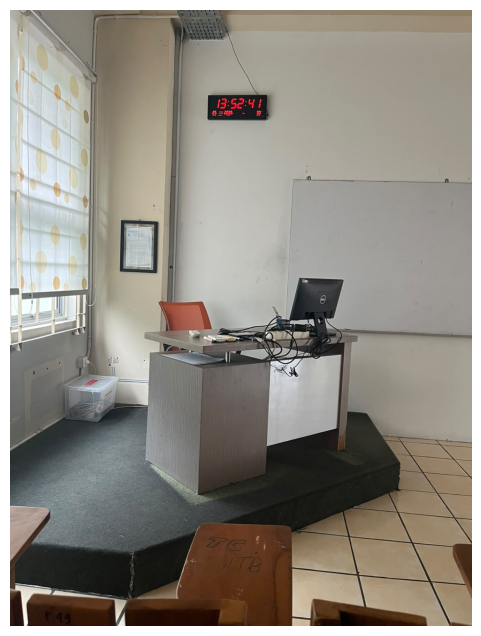

In [ ]:
# Path relatif dari folder proyek; ganti dengan path lengkap bila diperlukan.
ROBOFLOW_PHOTO_DIR = Path('Dataset_Roboflow/test')
# Pilih salah satu: path file foto atau path folder berisi foto.
PERSONAL_PHOTO_PATH = Path('E:\\Coding\\Python\\Computer_Vision\\Week_11\\New_Foto.jpeg')
# PERSONAL_PHOTO_PATH = Path('E:\\Coding\\Python\\Computer_Vision\\Week_11\\test')

# Pratinjau file; jika memilih folder, foto dipilih saat menjalankan Blok 05B.
if PERSONAL_PHOTO_PATH.is_file():
    plt.figure(figsize=(6, 8))
    plt.imshow(open_photo(PERSONAL_PHOTO_PATH))
    plt.axis('off')
    plt.show()

# Pilih tepat tiga model. Pilihan:
# yolov8n_pretrained, yolov8n_scratch, yolo11n_pretrained,
# yolo11n_scratch, maskrcnn_pretrained, maskrcnn_scratch
COMPARE_MODELS = ['yolov8n_pretrained', 'yolo11n_pretrained', 'maskrcnn_pretrained']

CONF_THRESHOLD = 0.14
IOU_THRESHOLD = 0.7
MASK_THRESHOLD = 0.5
IMAGE_SIZE = 1280
MAX_DETECTIONS = 20

SHOW_MASK = True
SHOW_BOX = True
SHOW_LABEL = True
SHOW_CONFIDENCE = True

## Blok 05A — Foto acak Roboflow
Jalankan cell ini untuk memilih satu foto dari `Dataset_Roboflow/test`. Lima panel memperlihatkan foto asli, ground truth dari `_annotations.coco.json`, dan prediksi tiga model pilihan pada foto yang sama. Ini visualisasi satu foto, bukan evaluasi dataset atau perhitungan metrik.

Foto: Dataset_Roboflow\test\335_jpeg.rf.2018a604fe9af2e499e4df6898308fb1.jpg
Ground truth: 12 objek
yolov8n_pretrained: 3 objek | 171.1 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,trash-bin,0.343767,2.966993,0.070898,509.832153,746.609070
1,2,wall-other-merged,0.221489,0.000000,0.000000,511.077118,740.384766
2,3,wall-other-merged,0.155686,163.377045,359.452240,236.570328,535.909058


yolo11n_pretrained: 1 objek | 176.2 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,table-merged,0.188724,0.0,660.083618,351.960693,768.0


maskrcnn_pretrained: 20 objek | 140.0 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,window-other,0.849879,170.209488,362.011353,236.876755,525.029419
1,2,window-other,0.692137,181.257050,364.614319,220.281738,436.840332
2,3,wall-other-merged,0.643030,314.931335,149.122055,490.934204,515.335632
3,4,wall-other-merged,0.633982,255.586472,452.413025,423.468109,606.450684
4,5,wall-other-merged,0.621166,26.737909,0.360410,461.746399,547.194214
5,6,window-other,0.602533,145.626282,343.054443,254.791672,531.436646
6,7,wall-other-merged,0.578536,114.424141,436.666138,161.497299,524.917542
7,8,wall-other-merged,0.576161,6.357383,0.000000,218.776718,691.096252
8,9,window-other,0.553131,109.983238,322.688171,177.896057,603.359314
9,10,wall-other-merged,0.462229,13.848027,63.175037,385.544525,723.965942


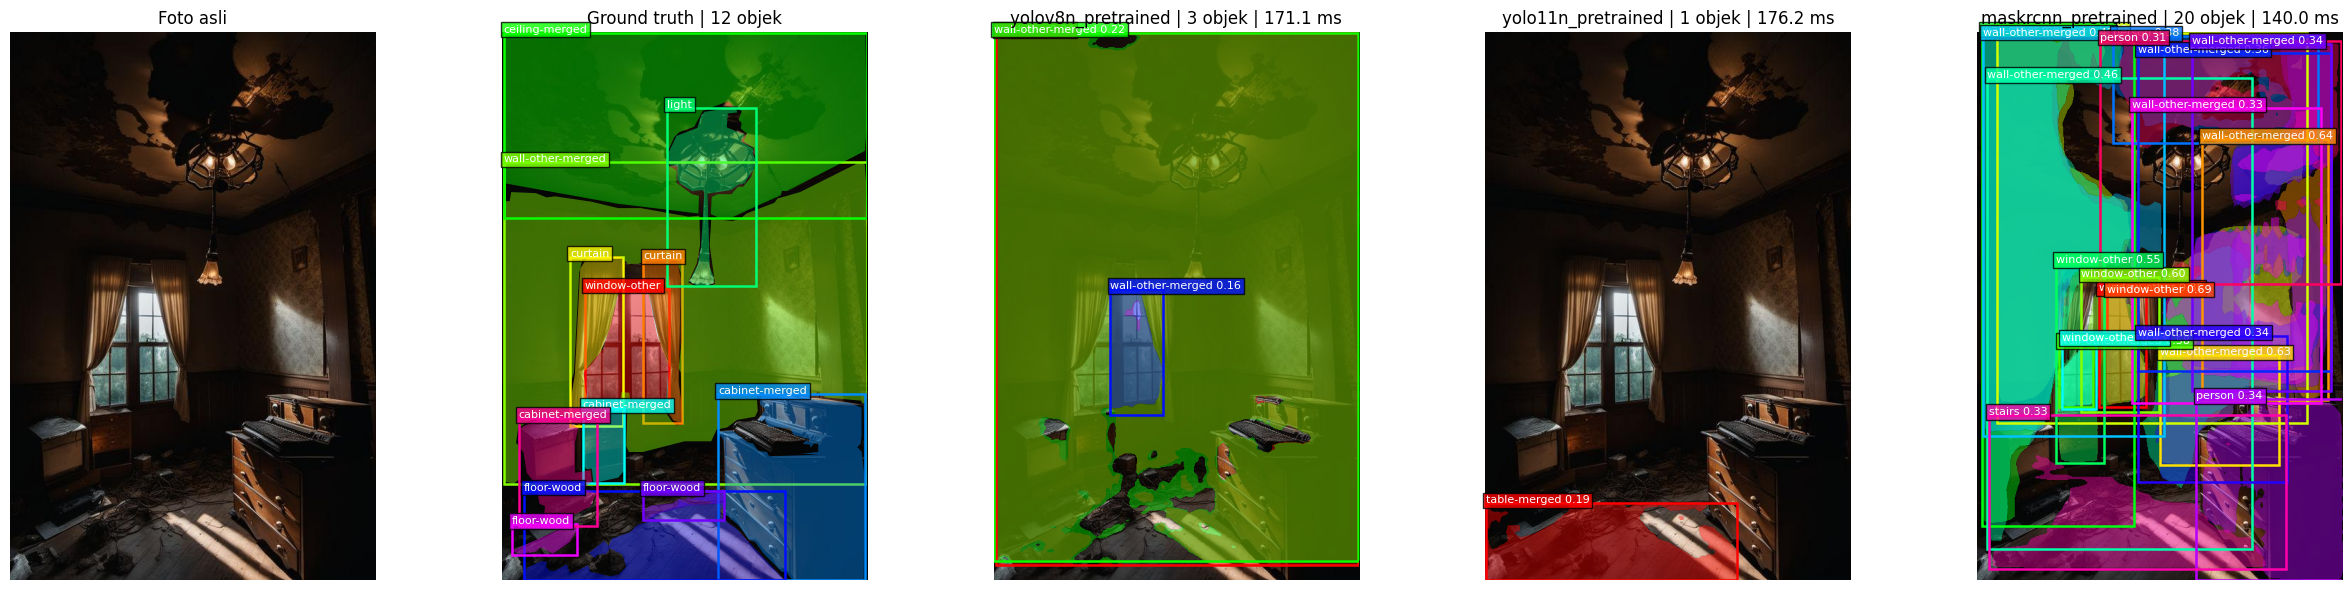

In [105]:
IMAGE_PATH = random_photo(ROBOFLOW_PHOTO_DIR)
compare_models(IMAGE_PATH, COMPARE_MODELS)

## Blok 05B — Foto pribadi
Jalankan cell ini untuk memproses `PERSONAL_PHOTO_PATH` di Blok 04. Jika path berupa folder, satu foto dipilih secara acak setiap kali cell dijalankan. Lima panel menampilkan foto asli, ground truth bila tersedia, dan prediksi tiga model. Anotasi dicari dalam `_annotations.coco.json` di folder foto, berdasarkan `file_name` atau `extra.name`.

Foto: E:\Coding\Python\Computer_Vision\Week_11\New_Foto.jpeg
Ground truth tidak tersedia untuk foto ini.
yolov8n_pretrained: 14 objek | 165.9 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,chair,0.724088,392.186584,756.616516,519.642029,831.548462
1,2,table-merged,0.595170,726.771301,1111.281616,1198.743774,1600.000000
2,3,wallet,0.445664,439.244232,1332.006226,733.826538,1599.309326
3,4,table-merged,0.431498,0.000000,1290.720337,98.089279,1591.169922
4,5,wall-other-merged,0.352452,369.882812,13.580704,1200.000000,850.234375
5,6,chair,0.322530,45.267506,1513.831177,272.380432,1599.542847
6,7,window-other,0.269137,511.587219,224.359009,666.398376,281.334412
7,8,chair,0.253221,142.870239,951.087524,275.925049,1068.045166
8,9,chair,0.252006,729.790039,695.041809,866.369019,804.403381
9,10,floor-other-merged,0.226504,731.852417,1116.925537,1199.024658,1600.000000


yolo11n_pretrained: 15 objek | 179.9 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,chair,0.846754,387.146057,757.183838,521.721130,831.688843
1,2,box,0.526120,352.825867,882.326172,675.285522,1251.937744
2,3,wall-other-merged,0.422320,209.082947,5.459366,437.189789,1016.067444
3,4,chair,0.366912,723.710449,698.194885,863.159058,873.365784
4,5,chair,0.314697,1152.646729,1388.695312,1200.000000,1521.887451
5,6,wall-other-merged,0.301226,430.868530,4.839859,1200.000000,825.669922
6,7,floor-wood,0.286732,0.177670,1289.117432,104.013580,1502.809448
7,8,wall-other-merged,0.211774,0.000000,0.000000,216.298523,1076.269531
8,9,table-merged,0.170636,0.173931,1289.710449,104.920792,1501.250244
9,10,box,0.163239,671.046753,886.217529,862.832031,1128.873169


maskrcnn_pretrained: 20 objek | 311.5 ms


,no,kelas,confidence,x_min,y_min,x_max,y_max
0,1,wall-other-merged,0.906325,80.578033,0.000000,477.309326,1147.791870
1,2,wall-other-merged,0.903498,230.519989,0.000000,1198.714355,1010.789429
2,3,window-other,0.831324,10.953827,68.712944,222.381012,1209.199463
3,4,wall-other-merged,0.787620,412.236603,22.821789,1155.012329,924.234497
4,5,chair,0.767778,11.224480,1285.332520,104.393387,1549.196167
5,6,wall-other-merged,0.717285,674.773499,898.647827,849.934021,1133.492554
6,7,box,0.689586,368.428802,864.905640,710.631958,1264.611816
7,8,wall-other-merged,0.686355,75.181892,0.000000,830.791260,1088.398438
8,9,trash-bin,0.671613,371.372620,864.142578,718.231873,1254.571289
9,10,wall-other-merged,0.650769,203.749466,0.000000,415.609436,1031.778076


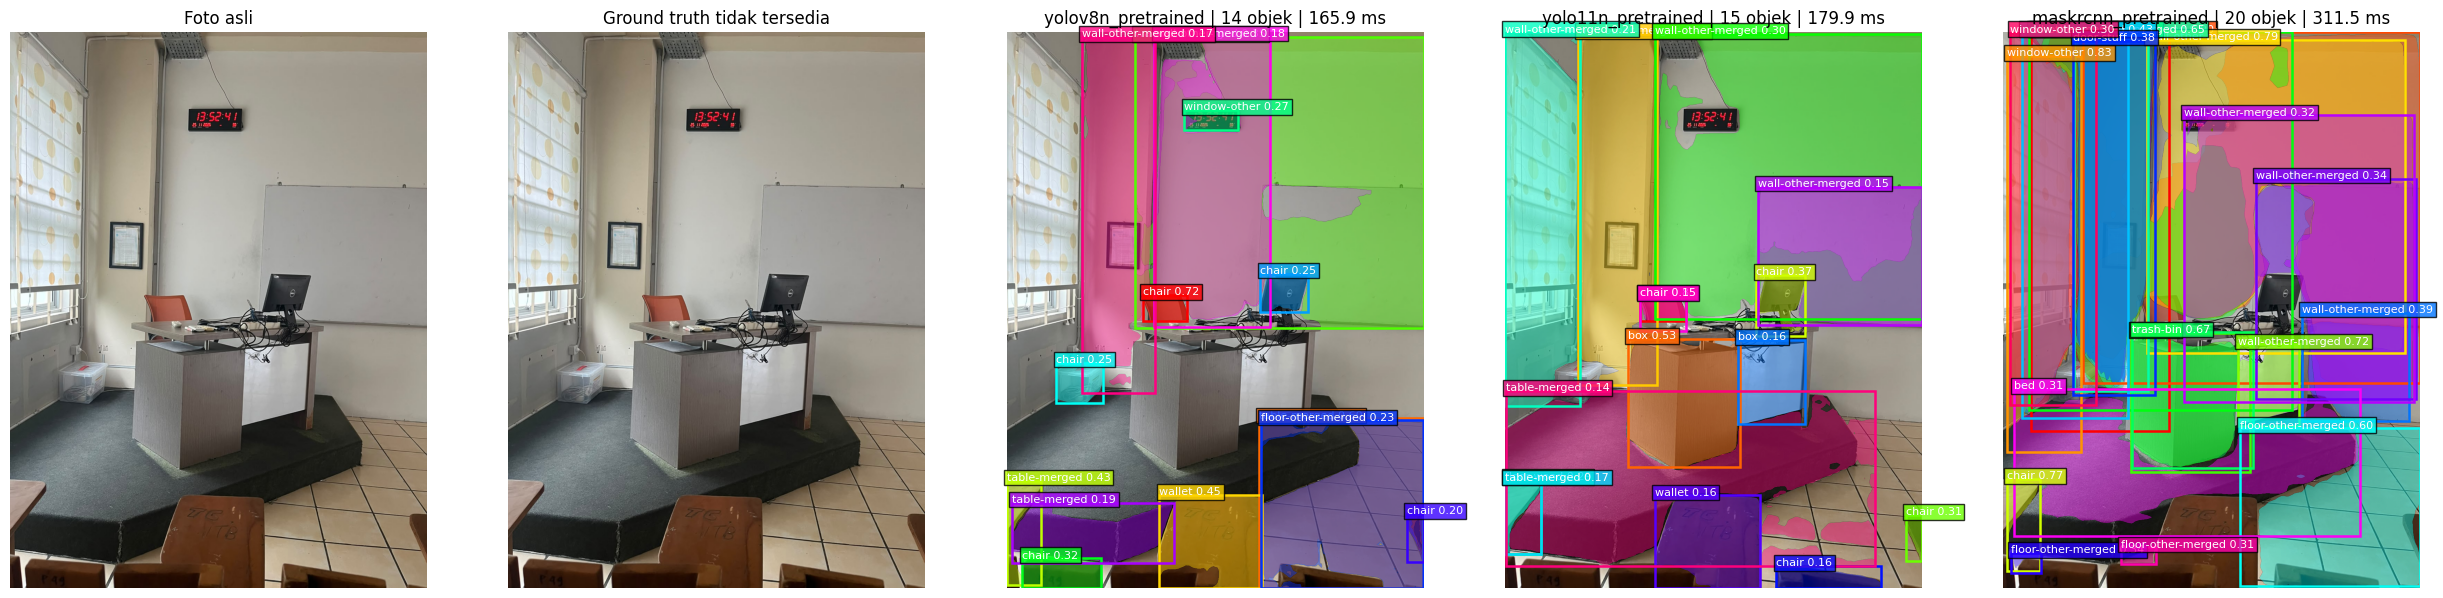

In [106]:
IMAGE_PATH = random_photo(PERSONAL_PHOTO_PATH) if PERSONAL_PHOTO_PATH.expanduser().is_dir() else PERSONAL_PHOTO_PATH
compare_models(IMAGE_PATH, COMPARE_MODELS)